# Módulo 04 · Visão geral e dados

**Retina em Foco — IA Embarcada** · IFPE Campus Palmares · Formação Técnica 2026.2 · 20 h (5 h presenciais) · Semanas 3–8

No Módulo 02 uma retinografia virou **um tensor 224×224×3** pronto para um modelo. Neste módulo construímos os modelos:
três classificadores de triagem — **retinopatia diabética (RD)**, **glaucoma** e **DMRI** — treinados no PC, quantizados e
executados **localmente num Raspberry Pi 5**, sem nuvem.

```
Módulo 02 ─ captura ─▶ qualidade ─▶ FOV ─▶ CLAHE ─▶ tensor uint8 (1, 224, 224, 3) ──────────────┐
                                                                                                  ▼
Módulo 04 ─ 01 CNNs ─▶ 02 transfer learning ─▶ 03 MobileNetV3-Small × EfficientNet-Lite0 ─▶ 04 quantização (TFLite)
                                                                                                  │
                         06 validação experimental ◀── 05 inferência no Raspberry Pi 5 (LiteRT) ◀─┘
```

| Notebook | Item da ementa | O que você vai fazer |
|---|---|---|
| `01_Redes_Convolucionais` | Aprendizado profundo e redes convolucionais | da convolução do Módulo 02 aos filtros *aprendidos*; treinar uma CNN do zero; sobreajuste e aumento de dados |
| `02_Transfer_Learning` | Transfer learning | o que o ImageNet "vê" numa retina; extrair características × ajuste fino; quanto dado cada estratégia precisa |
| `03_MobileNetV3_e_EfficientNet_Lite` | MobileNetV3-Small e EfficientNet-Lite0 | convolução separável, blocos MBConv, custo × acurácia; treinar os **três modelos** |
| `04_Quantizacao_e_TFLite` | Quantização e TensorFlow Lite | float32 → float16 → int8; tamanho, erro e latência; por que existe a versão *Lite* |
| `05_Inferencia_no_Raspberry_Pi` | Inferência em Raspberry Pi | LiteRT, threads, memória, triagem completa; roteiro da sessão no Lab Maker |
| `06_Validacao_Experimental` | Validação experimental dos modelos | limiar de triagem, ICs, **validação externa**, calibração, erros, Grad-CAM e o cartão do modelo |

> **Como usar:** execute as células na ordem. Os notebooks 03 e 06 gravam os modelos usados pelos seguintes; os modelos finais
> já vêm prontos em `modelos/`, então dá para começar por qualquer notebook. Cada um termina com **exercícios propostos** —
> base da entrega "Exercícios de treinamento e quantização — modelos de RD, glaucoma e DMRI" no AVEA.

## 1. Verificando o ambiente

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import logging
logging.getLogger("tensorflow").setLevel(logging.ERROR)   # oculta o aviso "sem GPU no Windows"
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from retina_iae import dados as D, visualizacao as V

V.configurar_estilo()

In [2]:
import platform, sys
import cv2, keras, tensorflow as tf
tf.get_logger().setLevel("ERROR")
import retina_pdi
from retina_iae.inferencia import runtime

print("Python        :", sys.version.split()[0], "|", platform.system(), platform.machine(), "|", os.cpu_count(), "núcleos lógicos")
print("TensorFlow    :", tf.__version__, "| Keras", keras.__version__, "| GPU:", tf.config.list_physical_devices("GPU") or "não (CPU)")
print("Inferência    :", runtime())
print("retina_pdi    :", retina_pdi.__version__, "(Módulo 02, commit fixado em requirements.txt)")
print("OpenCV/NumPy  :", cv2.__version__, "/", np.__version__)
print("Manifesto     :", "ok" if D.MANIFESTO.exists() else "AUSENTE — rode:  python scripts/download_data.py")
print("Cache 224 px  :", "ok" if (D.CACHE / "tensores_224_clahe.npy").exists() else "AUSENTE — rode:  python scripts/preparar_cache.py")

Python        : 3.12.10 | Windows AMD64 | 16 núcleos lógicos
TensorFlow    : 2.21.0 | Keras 3.15.1 | GPU: não (CPU)
Inferência    : ai_edge_litert
retina_pdi    : 0.1.0 (Módulo 02, commit fixado em requirements.txt)
OpenCV/NumPy  : 4.14.0 / 2.5.3
Manifesto     : ok
Cache 224 px  : ok


Sem GPU? Tudo bem: o TensorFlow não usa GPU no Windows nativo, e os modelos deste módulo foram escolhidos justamente por serem
**pequenos** — treinam em minutos numa CPU de laptop. (Com GPU, via WSL2 ou Linux, o mesmo código roda sem mudanças.)

## 2. As imagens

Cinco bases públicas, todas **reais e anonimizadas**, baixadas por `scripts/download_data.py` (≈ 1,7 GB baixados, ≈ 0,5 GB em disco).
Dos bancos citados no edital (Messidor-2, APTOS 2019, DDR, REFUGE, ADAM), usamos **APTOS 2019** e **DDR**; REFUGE e ADAM
exigem cadastro, e entram no lugar deles bases abertas com o mesmo papel (**G1020** para glaucoma; **ODIR** e **RFMiD** para DMRI).
O Messidor-2 fica como exercício (notebook 06).

In [3]:
man = D.carregar_manifesto()
print(f"{len(man):,} imagens · {man.fonte.nunique()} fontes".replace(",", "."))
tabela = man.pivot_table(index="fonte", columns="condicao", values="id", aggfunc="count", fill_value=0)
tabela = tabela[[c for c in ["normal", "rd", "glaucoma", "dmri", "ilegivel"] if c in tabela.columns]]
tabela["total"] = tabela.sum(axis=1)
tabela.loc["TOTAL"] = tabela.sum()
tabela

10.470 imagens · 5 fontes


condicao,normal,rd,glaucoma,dmri,ilegivel,total
fonte,,,,,,
APTOS,1805,1857,0,0,0,3662
DDR,200,300,0,0,50,550
G1020,724,0,296,0,0,1020
ODIR,2873,1608,284,266,0,5031
RFMiD,138,0,0,69,0,207
TOTAL,5740,3765,580,335,50,10470


| Fonte | Origem | Resolução aqui | Rótulos | Licença / uso | Papel neste módulo |
|---|---|---|---|---|---|
| **APTOS 2019** | triagem na Índia (Aravind), várias câmeras | 224×224 (espelho já reduzido) | grau de RD 0–4 (ICDR) | termos da competição Kaggle | **desenvolvimento** do modelo de RD |
| **DDR** | 147 hospitais na China, 42 câmeras | ≤ 1024 px | grau 0–4 + **5 = sem qualidade** | CC BY 4.0 | **externo** para RD; teste do controle de qualidade |
| **G1020** | clínica na Alemanha | 512 px | glaucoma × normal (diagnóstico clínico) | uso acadêmico | **externo** para glaucoma |
| **ODIR-5K** | hospitais na China, olho esquerdo e direito por paciente | 512×512 | normal, diabetes, glaucoma, DMRI, … | educacional/pesquisa | **desenvolvimento** de glaucoma e DMRI; **externo** de RD |
| **RFMiD** | Índia, 3 câmeras | ≤ 1024 px | 45 achados (multirrótulo) | CC BY 4.0 | **externo** para DMRI |

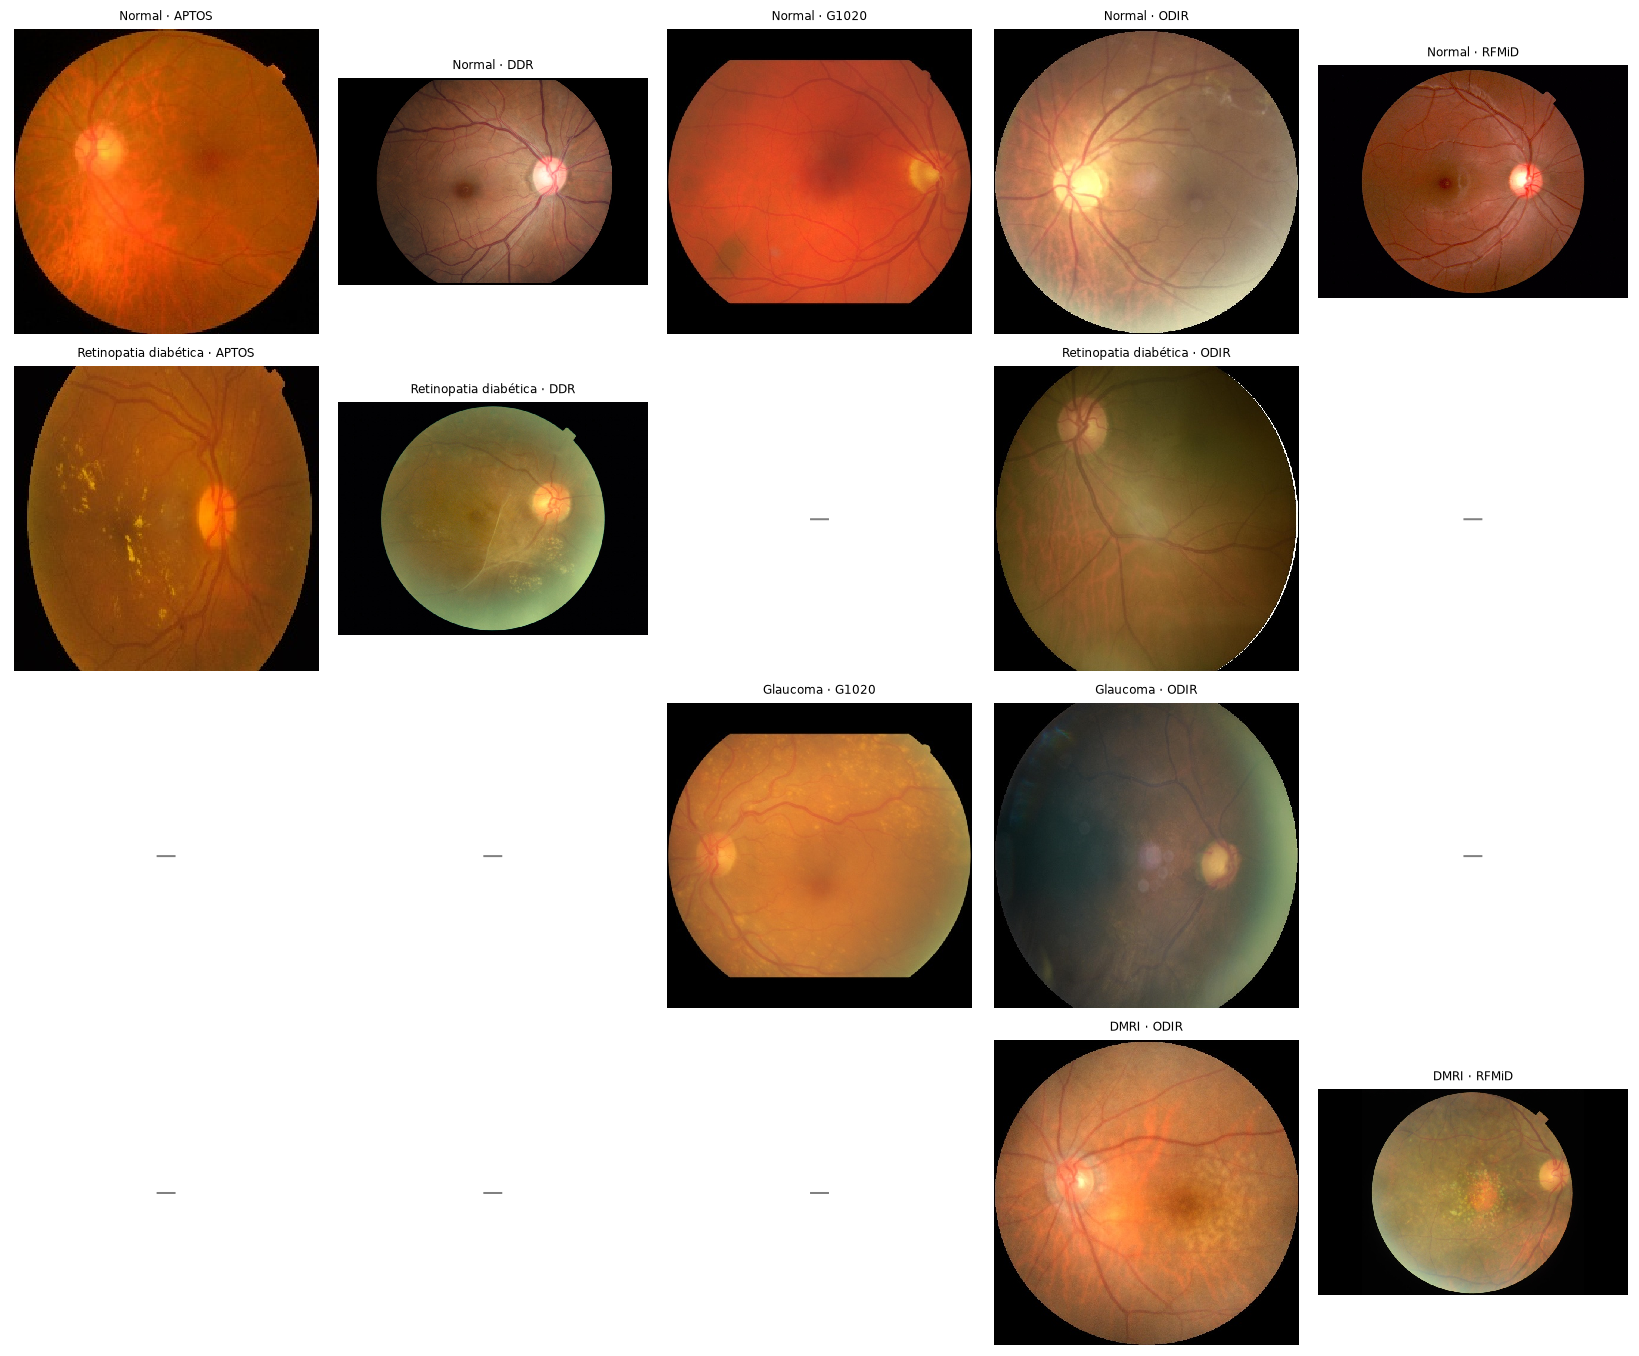

In [4]:
fontes = ["APTOS", "DDR", "G1020", "ODIR", "RFMiD"]
conds = ["normal", "rd", "glaucoma", "dmri"]
fig, axs = plt.subplots(len(conds), len(fontes), figsize=(3.0 * len(fontes), 3.1 * len(conds)))
for i, c in enumerate(conds):
    for j, f in enumerate(fontes):
        ax = axs[i, j]; ax.axis("off")
        sel = man[(man.condicao == c) & (man.fonte == f)]
        if c == "rd":
            sel = sel[sel.grau.astype(str).isin(["2", "3", "4", ""])]
        if len(sel):
            r = sel.sample(1, random_state=5).iloc[0]
            ax.imshow(D.carregar_rgb(r.arquivo)); ax.set_title(f"{D.NOMES_CONDICAO[c]} · {f}", fontsize=8)
        else:
            ax.text(0.5, 0.5, "—", ha="center", va="center", color="gray", fontsize=14)
fig.tight_layout(); V.salvar_figura(fig, "00_galeria"); plt.show()

Repare como **cada base tem uma "assinatura"**: formato do campo de visão (círculo inteiro, cortado em cima e embaixo),
cor dominante, brilho, nitidez. Uma rede neural percebe isso facilmente — e é por isso que, mais adiante, cada modelo é
treinado com positivos e negativos **da mesma fonte** e depois testado em **outra**.

## 3. Três tarefas, cada uma com dados de desenvolvimento e dados externos

O edital pede **um modelo por condição**. Cada tarefa é binária ("encaminhar ou não ao oftalmologista") e definida em `retina_iae.particoes`:

In [5]:
from retina_iae.particoes import TAREFAS
pd.DataFrame([{"tarefa": t, "modelo": c["nome"], "desenvolvimento": ", ".join(c["desenvolvimento"]),
               "externo": ", ".join(c["externo"]), "definição": c["descricao"]} for t, c in TAREFAS.items()]).set_index("tarefa")

,modelo,desenvolvimento,externo,definição
tarefa,,,,
rd,Retinopatia diabética referível,APTOS,"DDR, ODIR",RD moderada ou pior (grau ICDR ≥ 2) × sem RD o...
glaucoma,Glaucoma,ODIR,G1020,Glaucoma (diagnóstico declarado pela fonte) × ...
dmri,Degeneração macular relacionada à idade,ODIR,RFMiD,"DMRI × normal. No RFMiD, a DMRI pode coexistir..."


In [6]:
part = D.carregar_particoes()
resumo = (part.groupby(["tarefa", "particao"])
              .agg(imagens=("id", "count"), positivos=("alvo", "sum"), prevalencia=("alvo", "mean"))
              .reindex(["treino", "validacao", "teste", "externo"], level=1))
resumo["prevalencia"] = (100 * resumo.prevalencia).round(1).astype(str) + " %"
resumo

imagens  positivos prevalencia
tarefa   particao                                 
dmri     treino        2196        183       8.3 %
         validacao      475         42       8.8 %
         teste          468         41       8.8 %
         externo        207         69      33.3 %
glaucoma treino        2189        201       9.2 %
         validacao      484         41       8.5 %
         teste          484         42       8.7 %
         externo       1020        296      29.0 %
rd       treino        2563       1041      40.6 %
         validacao      549        223      40.6 %
         teste          550        223      40.5 %
         externo       4981       1848      37.1 %

* **Treino** (70 %): ajusta os pesos. **Validação** (15 %): escolhe época, hiperparâmetros e o **limiar** de triagem.
  **Teste** (15 %): uma única medida final, da mesma fonte. **Externo**: outra base, outra câmera, outro país —
  a pergunta que importa para o retinógrafo do projeto, que *também* será uma câmera nova.
* A divisão é **estratificada** (mesma prevalência nas três partições) e, no ODIR, **por paciente**: os dois olhos da mesma
  pessoa ficam juntos. Sem isso, o modelo poderia "reconhecer" no teste o olho irmão de uma imagem do treino:

In [7]:
odir = man[man.fonte == "ODIR"]
olhos = odir.groupby("paciente").size()
print(f"ODIR: {len(odir)} imagens de {len(olhos)} pacientes; {(olhos == 2).sum()} pacientes têm os dois olhos na base.")
dm = part[(part.tarefa == "dmri") & (part.particao != "externo")]
print("Pacientes da tarefa DMRI em mais de uma partição:", int((dm.groupby("paciente").particao.nunique() > 1).sum()))

ODIR: 5031 imagens de 2914 pacientes; 2117 pacientes têm os dois olhos na base.
Pacientes da tarefa DMRI em mais de uma partição: 0


## 4. O pré-processamento é o do Módulo 02 — byte a byte

Todas as imagens passam por `retina_pdi.pipeline.preparar_para_inferencia` (recorte do FOV, *padding* quadrado, 224×224 com
`INTER_AREA`, CLAHE na luminância) — **a mesma função** que o Raspberry Pi usa na triagem. O resultado fica num cache
(`data/cache/tensores_224_clahe.npy`, 1,6 GB, memória mapeada) para não repetir o trabalho a cada treino.

configuração: {'tamanho': 224, 'realce': 'clahe', 'normalizacao': 'uint8', 'recortar_fov': True} | tensores: (10470, 224, 224, 3) uint8


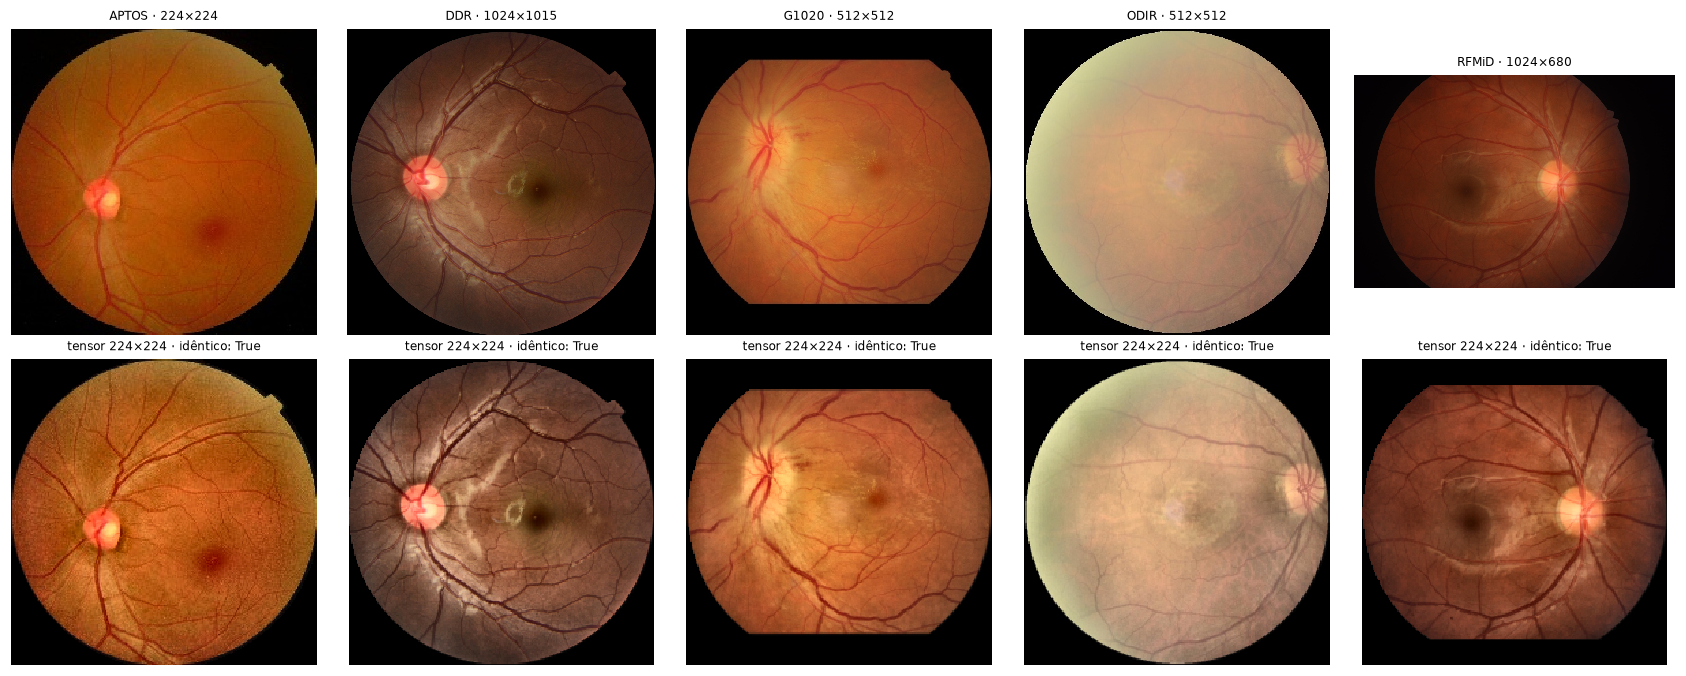

In [8]:
from retina_pdi import pipeline as P
cache = D.Cache()
print("configuração:", cache.cfg, "| tensores:", cache.x.shape, cache.x.dtype)

ids = man.groupby("fonte").sample(1, random_state=2).id.tolist()
fig, axs = plt.subplots(2, len(ids), figsize=(3.1 * len(ids), 6.2))
for j, i in enumerate(ids):
    r = man.set_index("id").loc[i]
    bruto = D.carregar_rgb(r.arquivo)
    x = P.preparar_para_inferencia(bruto, 224, "clahe", "uint8")[0]
    axs[0, j].imshow(bruto); axs[0, j].set_title(f"{r.fonte} · {bruto.shape[1]}×{bruto.shape[0]}", fontsize=8)
    axs[1, j].imshow(cache[i]); axs[1, j].set_title(f"tensor 224×224 · idêntico: {np.array_equal(x, cache[i])}", fontsize=8)
for a in axs.ravel(): a.axis("off")
fig.tight_layout(); plt.show()

`idêntico: True` é a **paridade treino × inferência** do notebook 06 do Módulo 02, verificada: o modelo vai ver no Pi exatamente
o tipo de tensor que viu no treino. O mesmo teste está em `tests/test_retina_iae.py::test_cache_bate_com_pipeline_do_modulo2`.

Uma decisão de projeto: o tensor guardado é **uint8 [0, 255]** e **cada modelo normaliza a própria entrada** na primeira camada
(MobileNetV3: [−1, 1] embutido no Keras; EfficientNet-Lite0: [−1, 1]; CNN do notebook 01: [0, 1]). Assim o mesmo tensor serve
para qualquer arquitetura — e o modelo quantizado em int8 recebe a imagem uint8 **sem conversão nenhuma** (notebook 04).

## 5. Cuidados ao interpretar estes dados

* **Rótulos herdados, não revistos.** Graus e diagnósticos vêm de cada base; ninguém neste projeto os revisou. São a "verdade
  declarada pela fonte" — com erros conhecidos (a concordância entre especialistas na graduação de RD está longe de 100 %).
* **"RD" não significa a mesma coisa em todo lugar.** No APTOS e no DDR há o **grau**, e o modelo aprende *RD referível*
  (moderada ou pior, grau ≥ 2 — o critério usual de encaminhamento). O ODIR só diz "diabetes", **incluindo RD leve**, que para
  o nosso modelo é negativa: espere sensibilidade menor ali, e não por culpa só do modelo.
* **G1020: rótulo clínico, nem sempre visível.** O diagnóstico vem do exame completo (pressão, campo visual, OCT), não só da foto. Numa validação
  cruzada *dentro* do G1020, características do ImageNet + regressão logística ficam em AUC ≈ 0,51 — o acaso. Ele foi planejado como base de
  desenvolvimento do glaucoma e virou a **externa**: é o teste mais duro do módulo (notebook 06).
* **RFMiD é multirrótulo.** Parte das DMRI tem outros achados junto (anotados em `rotulo_original`).
* **APTOS em 224×224.** O espelho aberto já vem reduzido; microaneurismas de 1–2 pixels nessa escala praticamente somem.
* **Amostras pequenas** (266 DMRI, 284 glaucomas no desenvolvimento): os intervalos de confiança do notebook 06 são largos.
  Resultados são **ilustrativos**, não estimativas de desempenho clínico.
* **Ética.** Somente bases públicas e anonimizadas; sem procedimentos com seres humanos (Edital nº 14/2026, §2.3.2). Respeite as
  licenças e cite as fontes (`docs/DADOS.md`).

## 6. Convenções e metas

| Objeto | Convenção |
|---|---|
| tensor de entrada | `uint8` (N, 224, 224, 3), RGB, do cache ou de `retina_pdi` — **nunca** normalizado fora do modelo |
| saída do modelo | `float32` em [0, 1] = P(condição); "encaminhar" se P ≥ limiar escolhido na validação |
| dados | `D.conjunto(tarefa, particao)` → `(X, y, tabela)` |
| pacote | `retina_iae.modelos`, `.treino`, `.conversao` (precisam de TensorFlow) · `.inferencia`, `.triagem` (só LiteRT — rodam no Pi) · `.metricas`, `.explicacao`, `.visualizacao` |
| modelos finais | `modelos/*.tflite` + `modelos/config_triagem.json` (limiares e pré-processamento), versionados no Git |

| Meta do edital (Tabela 3) | Onde é trabalhada |
|---|---|
| ≤ 3 s por condição na inferência embarcada | notebooks **04** e **05**; `scripts/benchmark.py` no Pi |
| RAM ≤ 512 MB por inferência | notebook **05** |
| três modelos de triagem (RD, glaucoma, DMRI) rodando localmente | notebooks **03**, **04** e `retina_iae.triagem` |
| validação experimental dos modelos | notebook **06** (teste interno, externo, ICs, limiar, calibração) |

## Exercícios propostos

1. **Assinatura das fontes.** Calcule a cor média (R, G, B) dentro do FOV dos tensores de cada fonte e faça um gráfico.
   Um classificador *de fonte* acertaria quanto só com esses três números? (Dica: `sklearn.linear_model.LogisticRegression`.)
2. **Vazamento por paciente.** Refaça a divisão da tarefa DMRI **por imagem** (ignorando `paciente`). Quantos pacientes
   passam a ter um olho no treino e outro no teste?
3. **Prevalência.** Por que a prevalência de glaucoma no desenvolvimento (ODIR, ≈ 9 %) é tão diferente da do externo (G1020, ≈ 29 %)?
   Que métrica do notebook 06 muda com isso e qual não muda?
4. **Graus do DDR.** Monte a tabela grau × partição da tarefa RD no DDR. Onde estão as imagens de grau 5 e por que elas
   **não** fazem parte da tarefa?